In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [6]:
image = cv2.imread(r'C:\Users\vaibh\Downloads\serene-samurai-amidst-cherry-blossoms-moonlit-lake.jpg')

if image is None:
    raise FileNotFoundError("Image not Found")

In [7]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [8]:
mask = np.zeros(image.shape[:2], np.uint8)

In [9]:
bg_model = np.zeros((1, 65), np.float64)
fg_model = np.zeros((1, 65), np.float64)

In [10]:
height, width = image.shape[:2]
rect = (20, 20, width - 40, height - 40)

In [11]:
cv2.grabCut(image, mask, rect, bg_model, fg_model, 5, cv2.GC_INIT_WITH_RECT)

(array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(3072, 5376), dtype=uint8),
 array([[2.66397091e-01, 5.09232341e-02, 2.56776458e-01, 2.88585417e-01,
         1.37317800e-01, 4.25388184e+01, 1.89792434e+01, 1.48915937e+01,
         2.16937833e+02, 2.05546022e+02, 2.51877543e+02, 5.43572628e+01,
         2.16522875e+01, 9.58985381e+01, 1.06788066e+02, 5.97888358e+01,
         6.42313248e+01, 7.88854389e+01, 4.88466935e+01, 1.81787899e+02,
         1.49611389e+02, 8.50136446e+01, 5.23883013e+01, 8.50136446e+01,
         5.20730913e+01, 3.28963901e+01, 5.23883013e+01, 3.28963901e+01,
         2.78712709e+01, 4.83626568e+00, 4.40819183e+00, 1.22652352e+00,
         4.40819183e+00, 3.11077710e+01, 3.01944312e+00, 1.22652352e+00,
         3.01944312e+00, 3.17902028e+00, 1.71557782e+02, 1.02246845e+02,
         7.90365604e+01,

In [12]:
mask2 = np.where((mask == 2) | (mask == 0), 0, 1).astype('uint8')

In [13]:
result = image_rgb * mask2[:, :, np.newaxis]

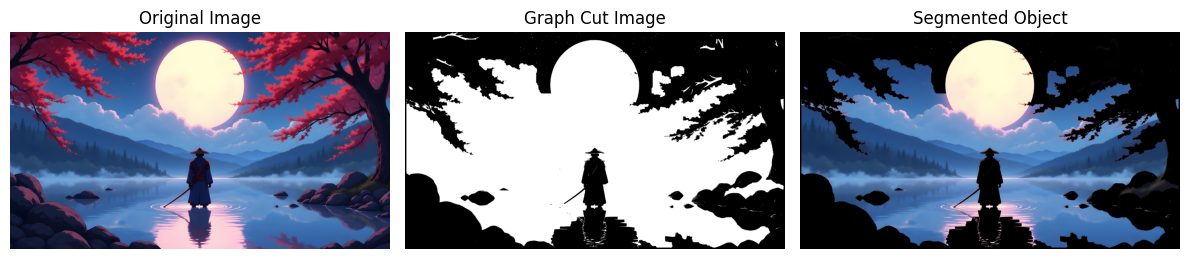

In [16]:
plt.figure(figsize = (12, 4))
plt.subplot(1, 3, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask2, cmap="gray")
plt.title("Graph Cut Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(result)
plt.title("Segmented Object")
plt.axis("off")

plt.tight_layout()
plt.show()